In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from neurogym.wrappers import ScheduleEnvs, Monitor
from neurogym.utils import plot_env, RandomSchedule, SequentialSchedule
from neurogym.envs import get_collection
from torch.nn import functional as F

from IPython.display import clear_output
warnings.filterwarnings("ignore")
clear_output()

In [2]:
# Environment parameters
# This setting is low to speed up testing, we recommend setting it to at least 1000
EVAL_TRIALS = 100
dt = 100
dim_ring = 2  # Number of choices in the ring representation

rewards = {
    "abort": -0.1,
    "correct": +1.0,
    "fail": 0.0
}
sigma = 1.0 # Standard deviation of the Gaussian noise in the ring representation

Trial timing (in milliseconds):
{'fixation': 500, 'stimulus': 500, 'delay': 500, 'decision': 500}

Observation space structure:
Box(-inf, inf, (5,), float32)

Action space structure:
Discrete(3)
Action mapping:
{'fixation': 0, 'choice': range(1, 3)}


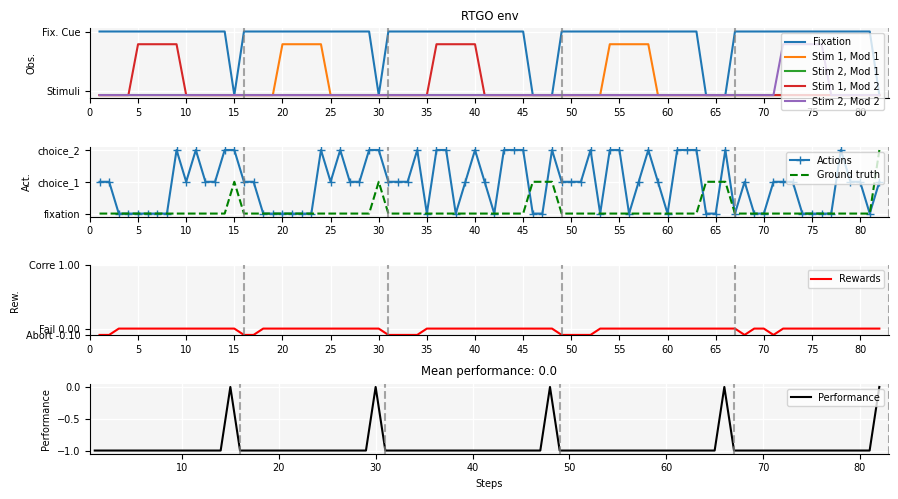

In [3]:
### dm1
timing = {
    "fixation": ("uniform", (200, 500)),
    "stimulus": ("choice", [200, 400, 600]),
    "decision": 200,
}
kwargs = {
    "dt": dt,
    "dim_ring": dim_ring,
    "rewards": rewards,
    # "timing": timing,
    # "sigma": sigma,
}
task = "dlygo"
task = f"yang19.{task}-v0"
env1 = ngym.make(task, **kwargs)

# Print environment specifications
print("Trial timing (in milliseconds):")
print(env1.timing)

print("\nObservation space structure:")
print(env1.observation_space)

print("\nAction space structure:")
print(env1.action_space)
print("Action mapping:")
print(env1.action_space.name)

obs, info = env1.reset()

stim1 = [f'Stim {i}, Mod 1' for i in range(1, kwargs['dim_ring'] + 1)]
stim2 = [f'Stim {i}, Mod 2' for i in range(1, kwargs['dim_ring'] + 1)]

# Visualize example trials
fig = plot_env(
    env1,
    name='RTGO',
    ob_traces=['Fixation'] + stim1 + stim2,
    num_trials=5,
    plot_performance=True,
    fig_kwargs={'figsize': (9, 5)},
)

Trial timing (in milliseconds):
{'fixation': ('uniform', (200, 500)), 'stimulus': ('choice', [200, 400, 600]), 'decision': 200}

Observation space structure:
Box(-inf, inf, (5,), float32)

Action space structure:
Discrete(3)
Action mapping:
{'fixation': 0, 'choice': range(1, 3)}


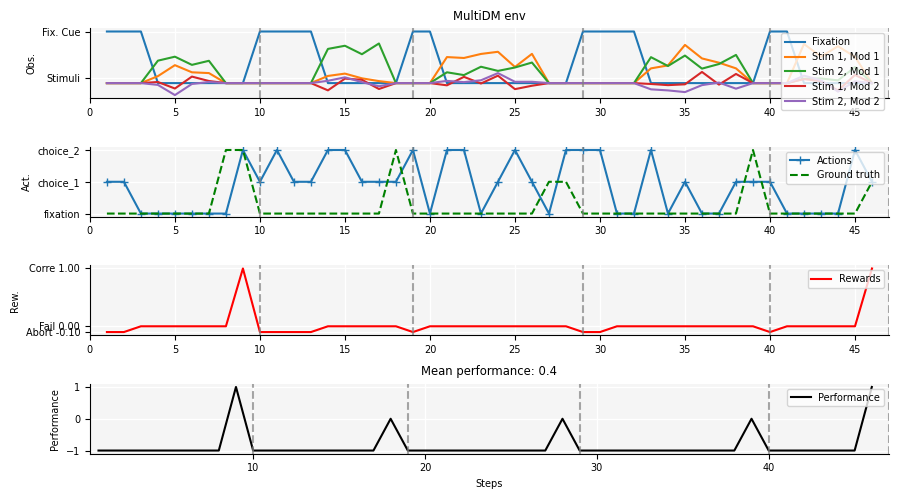

In [4]:
### multidm
timing = {
    "fixation": ("uniform", (200, 500)),
    "stimulus": 500,
    "decision": 200,
}
kwargs = {
    "dt": dt,
    "dim_ring": dim_ring,
    # "rewards": rewards,
    # "timing": timing,
    # "sigma": sigma,
}
task = "dm1"
task = f"yang19.{task}-v0"
env2 = ngym.make(task, **kwargs)

# Print environment specifications
print("Trial timing (in milliseconds):")
print(env2.timing)

print("\nObservation space structure:")
print(env2.observation_space)

print("\nAction space structure:")
print(env2.action_space)
print("Action mapping:")
print(env2.action_space.name)

obs, info = env2.reset()

stim1 = [f'Stim {i}, Mod 1' for i in range(1, kwargs['dim_ring'] + 1)]
stim2 = [f'Stim {i}, Mod 2' for i in range(1, kwargs['dim_ring'] + 1)]

# Visualize example trials
fig = plot_env(
    env2,
    name='MultiDM',
    ob_traces=['Fixation'] + stim1 + stim2,
    num_trials=5,
    plot_performance=True,
    fig_kwargs={'figsize': (9, 5)},
)

In [5]:

from pdm_model import EISepLSTM, Net, load_model, SimpleNet

device = 'cuda' if torch.cuda.is_available() else 'cpu'
ob_size = env1.observation_space.shape[0]
act_size = env1.action_space.n
# net = Net(num_h=64, ob_size=ob_size, act_size=act_size).to(device)
# net = Net(num_h=64, ob_size=ob_size, act_size=act_size).to(device)


In [6]:
a = np.array([1, 2, 3])
a_cc = np.random.randn(10,3,3)
b = a.reshape(1,1,-1).repeat(a_cc.shape[0], 0).repeat(a_cc.shape[1], 1)
print(b)

[[[1 2 3]
  [1 2 3]
  [1 2 3]]

 [[1 2 3]
  [1 2 3]
  [1 2 3]]

 [[1 2 3]
  [1 2 3]
  [1 2 3]]

 [[1 2 3]
  [1 2 3]
  [1 2 3]]

 [[1 2 3]
  [1 2 3]
  [1 2 3]]

 [[1 2 3]
  [1 2 3]
  [1 2 3]]

 [[1 2 3]
  [1 2 3]
  [1 2 3]]

 [[1 2 3]
  [1 2 3]
  [1 2 3]]

 [[1 2 3]
  [1 2 3]
  [1 2 3]]

 [[1 2 3]
  [1 2 3]
  [1 2 3]]]


In [7]:
def train(env, net, env_vec):
    seq_len = 100
    batch_size = 32
    EPOCHS = 2000
    net.train()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(net.parameters(), lr=1e-2)
    dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

    running_loss = 0.0
    running_entropy = 0.0
    running_decoding_loss = 0.0

    loss_log = np.zeros((EPOCHS, 3))
    gradient_log = np.zeros((EPOCHS, 1))

    for i in range(EPOCHS):
        # net.set_temperature(get_temperature(i))
        # if i % 10 == 9:
            # print('Epoch:', i+1, 'Temperature:', net.temperature)
        inputs, labels = dataset()

        inputs = np.concatenate([inputs, env_vec.reshape(1,1,-1).repeat(inputs.shape[0], 0).repeat(inputs.shape[1],1)], axis=-1)
        inputs = torch.from_numpy(inputs).type(torch.float).to(device)
        labels = torch.from_numpy(labels.flatten()).type(torch.long).to(device)

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs, eimask_logit, hidden = net(inputs)

        decoding_loss = criterion(outputs.view(-1, act_size), labels)


        loss = decoding_loss

        if net.entropy_loss:
            eimask_prob = F.softmax(eimask_logit, dim=-1)
            eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
            entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization
            running_entropy += entropy_loss.item()
            loss_log[i, 2] = entropy_loss.item()
        else:
            entropy_loss = 0.0

        loss += entropy_loss * 1

        loss.backward()
        gradient_log[i] = net.lstm.Wrec_free.grad.norm(2).item()
        optimizer.step()

        loss_log[i, 0] = loss.item()
        loss_log[i, 1] = decoding_loss.item()

        # print statistics
        running_loss += loss.item()
        running_decoding_loss += decoding_loss.item()
        if (i+1) % 100 == 0:
            print('{:d} loss: {:0.5f}'.format(i+1, running_loss / 100))
            print('Entropy loss: {:0.5f}, Decoding loss: {:0.5f}'.format(
                running_entropy / 100, running_decoding_loss / 100))
            running_loss = 0.0
            running_entropy = 0.0
            running_decoding_loss = 0.0

    print('Finished Training')
    return net, loss_log, gradient_log

def test(env, net, env_vec):
    perf = 0
    num_trial = 200
    net.eval()
    for i in range(num_trial):
        env.seed(i)
        env.new_trial()
        ob, gt = env.ob, env.gt
        ob = ob[:, np.newaxis, :]  # Add batch axis
        ob = np.concatenate([ob, env_vec.reshape(1,1,-1).repeat(ob.shape[0], 0).repeat(ob.shape[1],1)], axis=-1)
        inputs = torch.from_numpy(ob).type(torch.float).to(device)
        action_pred = net(inputs)[0]
        action_pred = action_pred.cpu().detach().numpy()
        action_pred = np.argmax(action_pred, axis=-1)
        perf += gt[-1] == action_pred[-1, 0]
    perf /= num_trial

    return perf

def continual_learning(envs, net, prefix=''):
    """
    Continual learning on a sequence of environments.
    """
    test_perfs = np.zeros((len(envs), len(envs)))
    env_vecs = np.eye(len(envs))
    for i, env in enumerate(envs):
        # print(f'Training on environment {i}...')
        net, loss_log, gradient_log = train(env, net, env_vecs[i])
        plot_log(loss_log, f'./output/continual_learning_supervised/loss_log_env{i}.png', ['Total loss', 'Decoding loss', 'Entropy loss'])
        plot_log(gradient_log, f'./output/continual_learning_supervised/gradient_log_env{i}.png', ['Gradient norm'])
        for j, env_test in enumerate(envs):
            perf = test(env_test, net, env_vecs[j])
            test_perfs[i, j] = perf
            # print(f'Test performance on env {j} after training on env {i}: {perf:.3f}')
    return test_perfs

def plot_sequential_performance(test_perf_EI, test_perf_simple, seed, env_names):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    for i in range(len(env_names)):
        ax[0].plot(test_perf_EI[:,i], label=f'{env_names[i]} acc')
        ax[1].plot(test_perf_simple[:,i], label=f'{env_names[i]} acc')
    ax[0].set_title('EI-RNN')
    ax[1].set_title('Simple RNN')
    for i in range(2):
        ax[i].set_xticks(range(len(env_names)))
        ax[i].set_xticklabels(env_names)
        # ax[i].set_xmargin(0)
        ax[i].set_xlabel('Training environment')
        ax[i].set_ylabel('Test performance')
        ax[i].legend()
    plt.tight_layout()
    plt.savefig(f'./output/sequential_performance_seed{seed}.png')

def plot_log(log, dir, items):
    fig, ax = plt.subplots(1, 1, figsize=(6, 3))
    for i in range(log.shape[1]):
        ax.plot(log[:, i], label=items[i])
    ax.set_xlabel('Epoch')
    ax.legend()
    plt.tight_layout()
    plt.savefig(dir)
    return


In [8]:
task_ids = ["go", "dlygo", "anti", "dlyanti"]
task = [f"yang19.{task}-v0" for task in task_ids]
envs = [ngym.make(t, **kwargs) for t in task]

100 loss: 0.89663
Entropy loss: 0.60977, Decoding loss: 0.89663
200 loss: 0.31697
Entropy loss: 0.29636, Decoding loss: 0.31697
300 loss: 0.14160
Entropy loss: 0.12620, Decoding loss: 0.14160
400 loss: 0.08367
Entropy loss: 0.06847, Decoding loss: 0.08367
500 loss: 0.05888
Entropy loss: 0.04386, Decoding loss: 0.05888
600 loss: 0.04599
Entropy loss: 0.03087, Decoding loss: 0.04599
700 loss: 0.03752
Entropy loss: 0.02306, Decoding loss: 0.03752
800 loss: 0.03264
Entropy loss: 0.01795, Decoding loss: 0.03264
900 loss: 0.02934
Entropy loss: 0.01440, Decoding loss: 0.02934
1000 loss: 0.02662
Entropy loss: 0.01183, Decoding loss: 0.02662
1100 loss: 0.02422
Entropy loss: 0.00990, Decoding loss: 0.02422
1200 loss: 0.02307
Entropy loss: 0.00841, Decoding loss: 0.02307
1300 loss: 0.02243
Entropy loss: 0.00723, Decoding loss: 0.02243
1400 loss: 0.02104
Entropy loss: 0.00628, Decoding loss: 0.02104
1500 loss: 0.01982
Entropy loss: 0.00550, Decoding loss: 0.01982
1600 loss: 0.01959
Entropy loss: 0

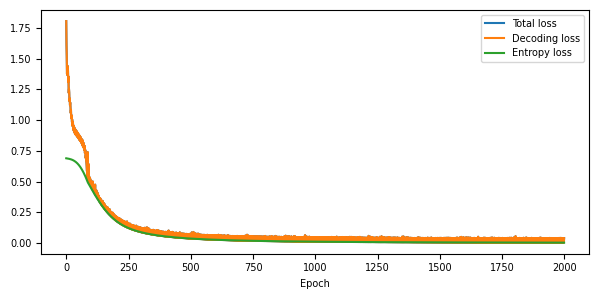

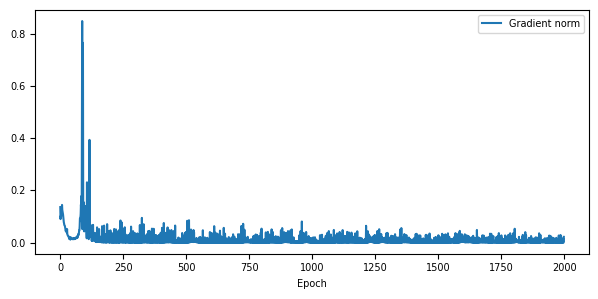

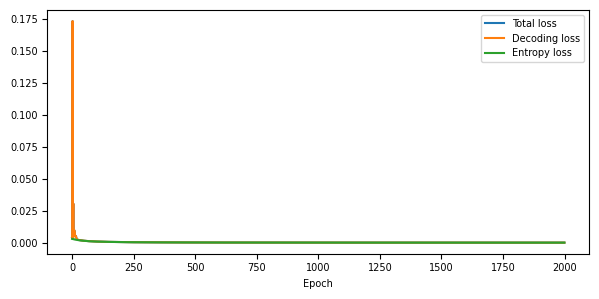

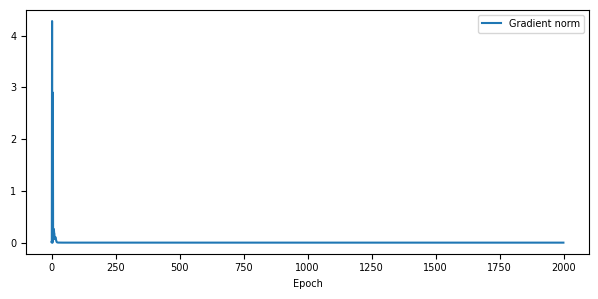

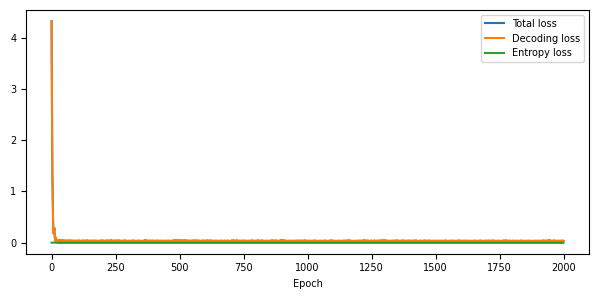

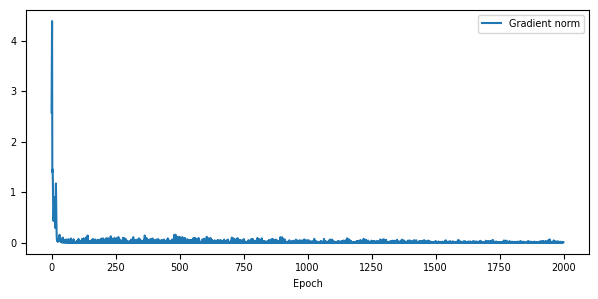

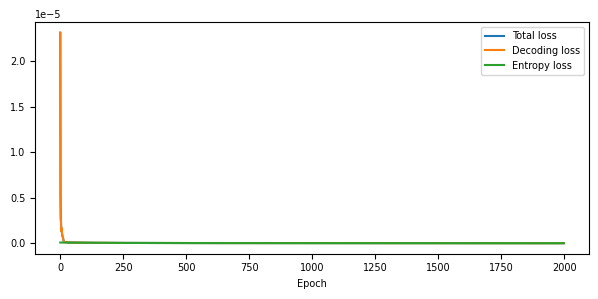

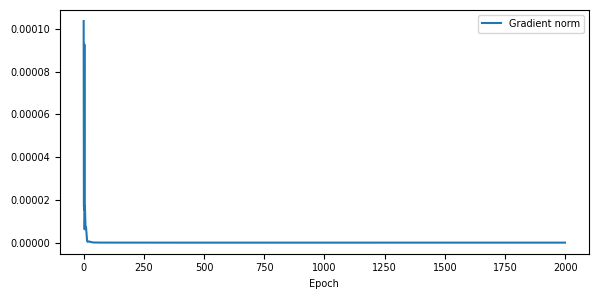

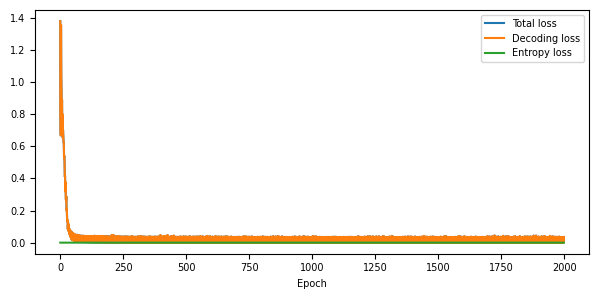

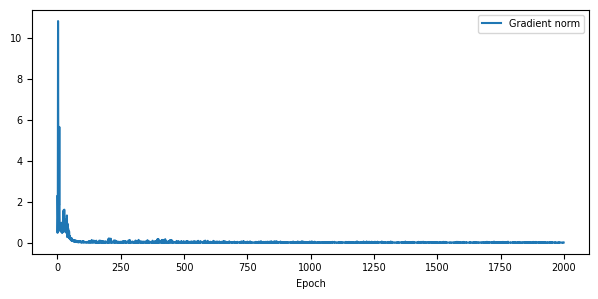

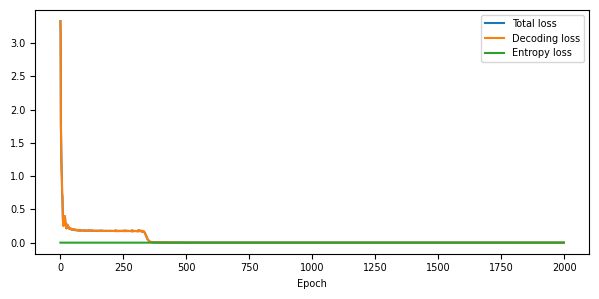

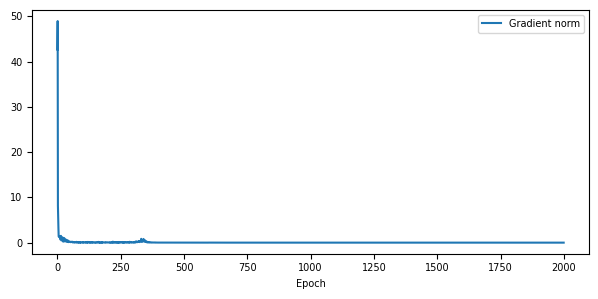

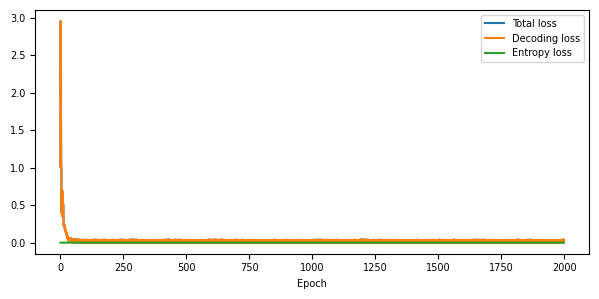

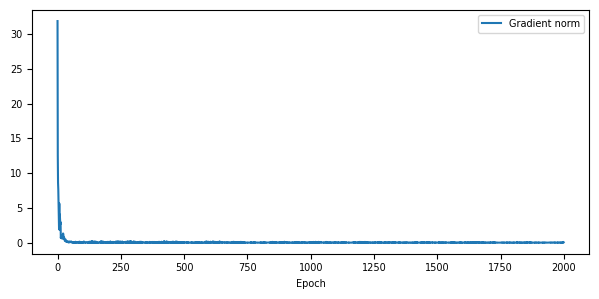

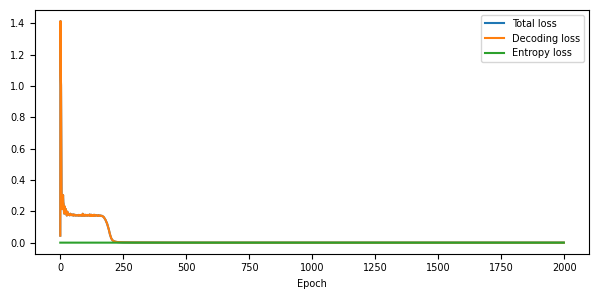

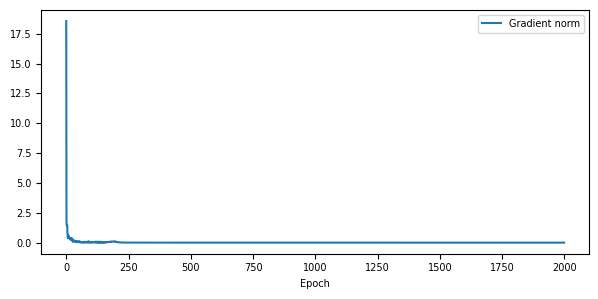

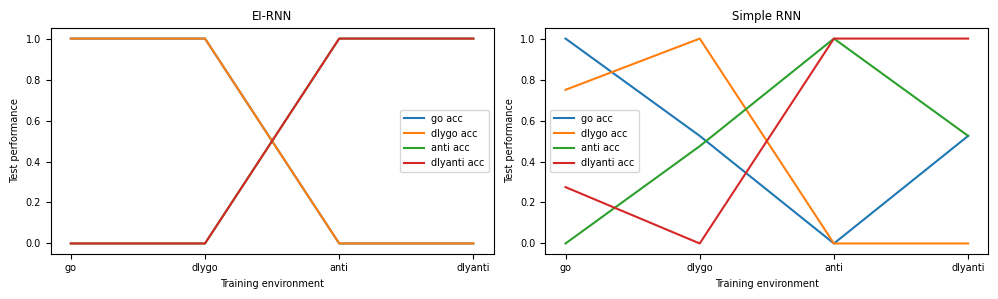

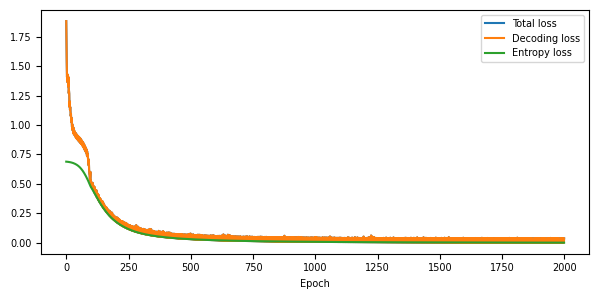

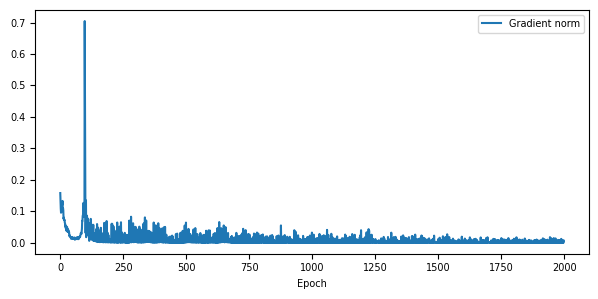

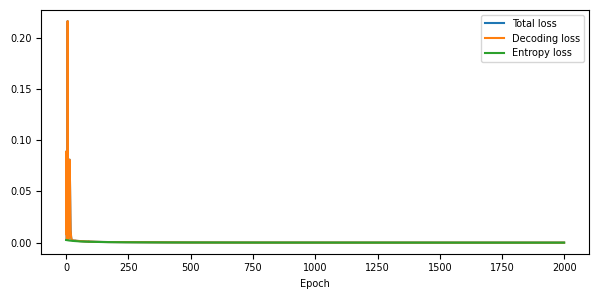

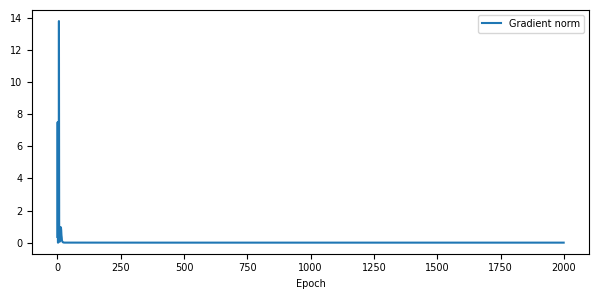

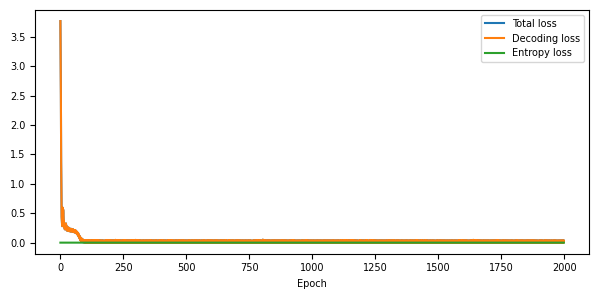

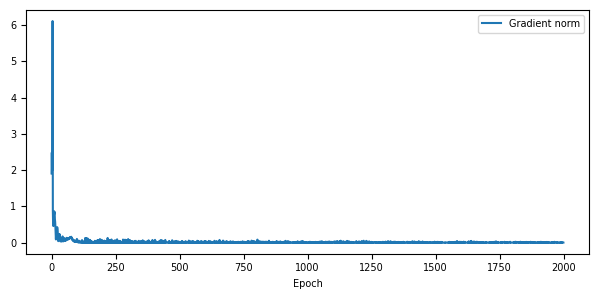

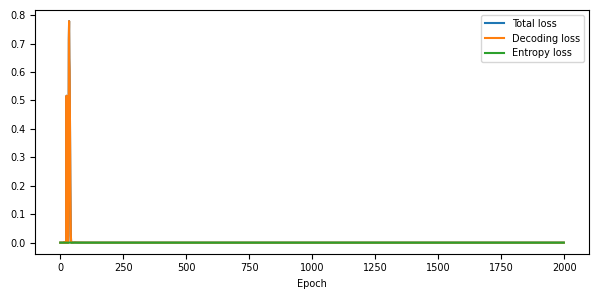

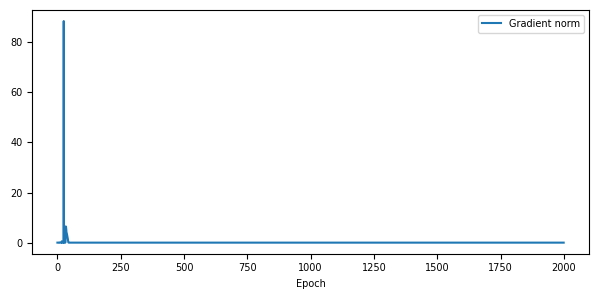

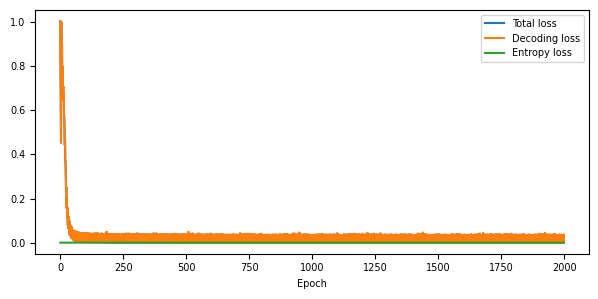

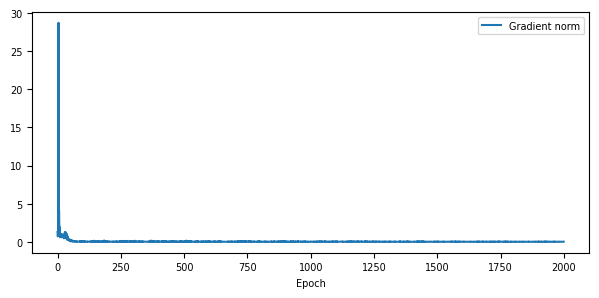

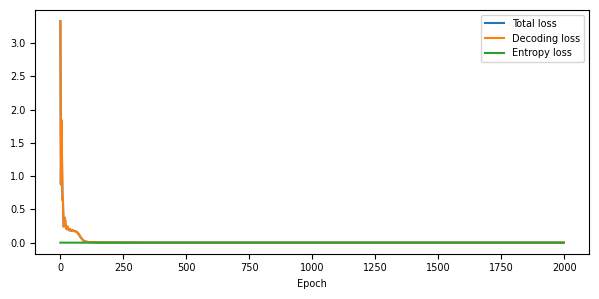

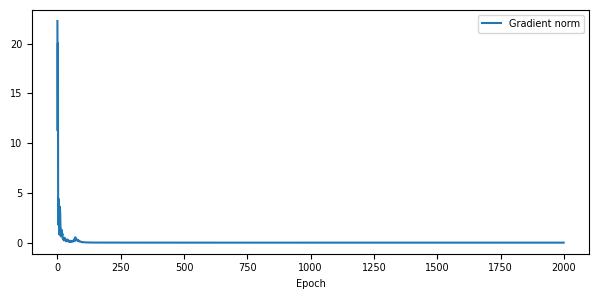

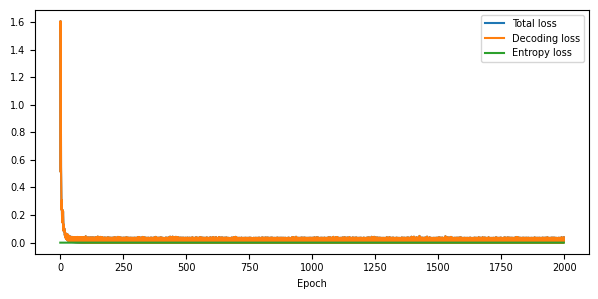

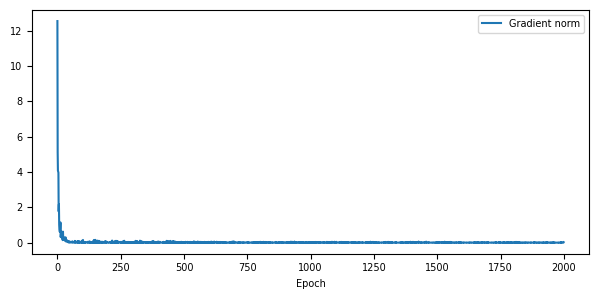

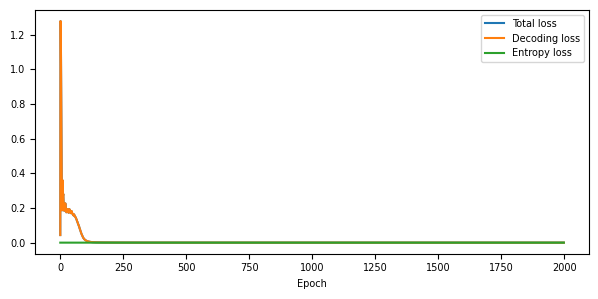

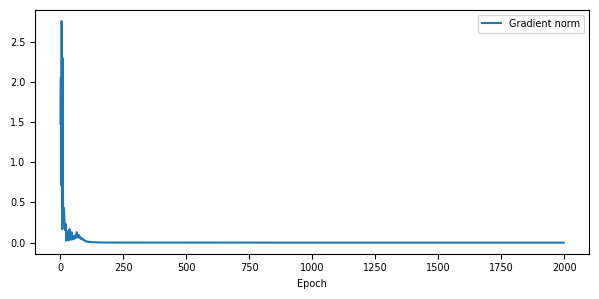

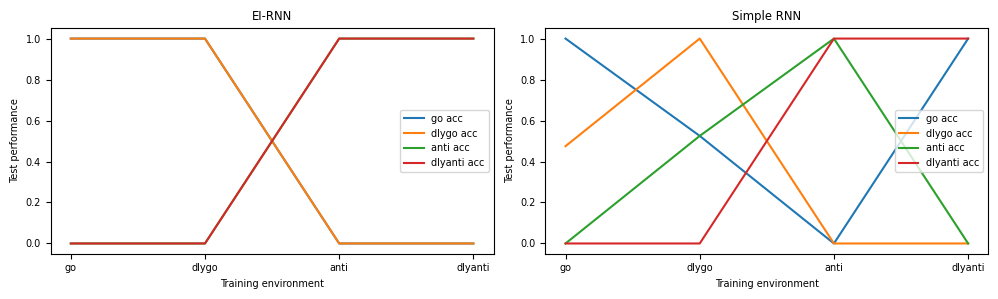

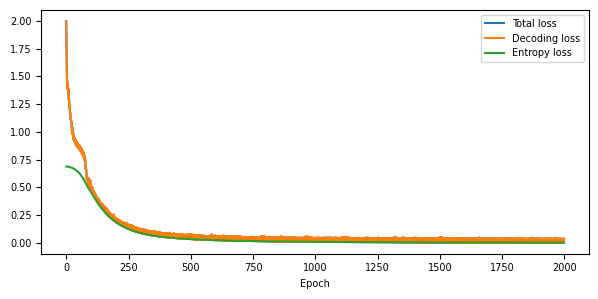

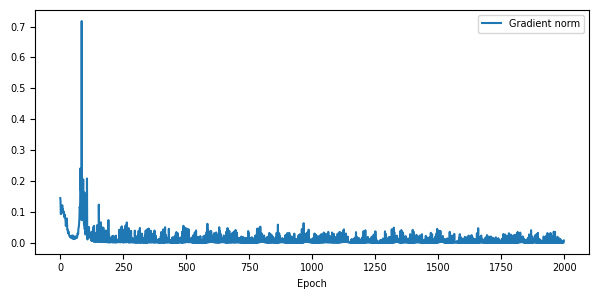

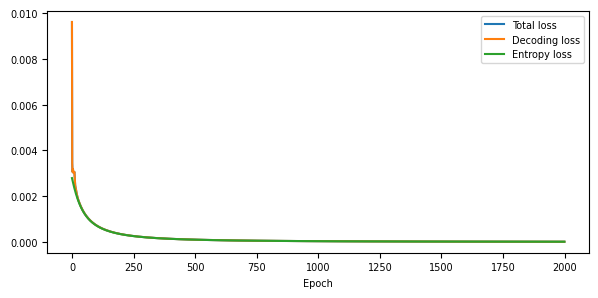

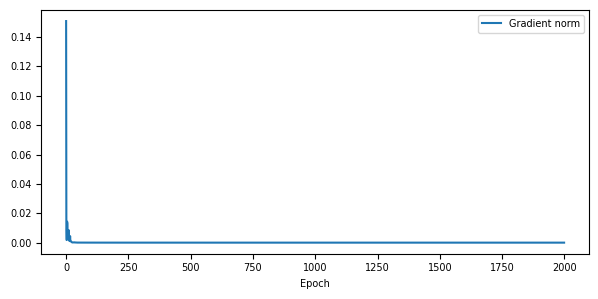

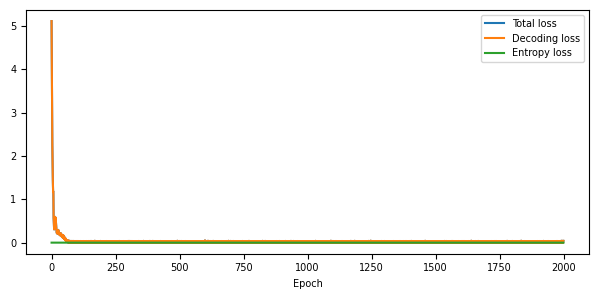

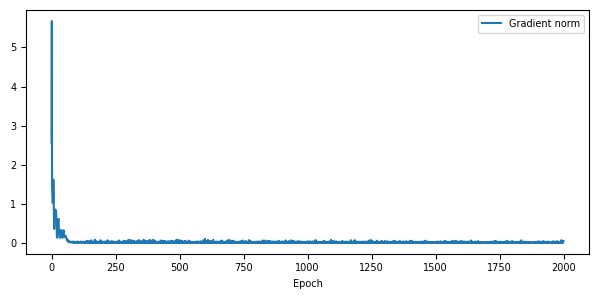

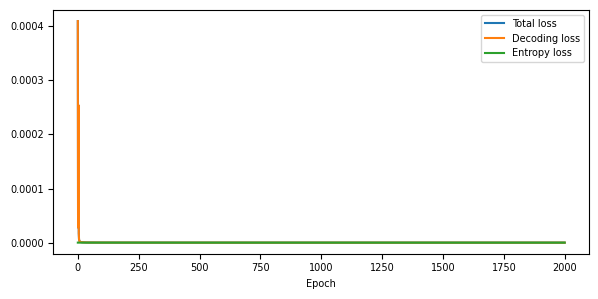

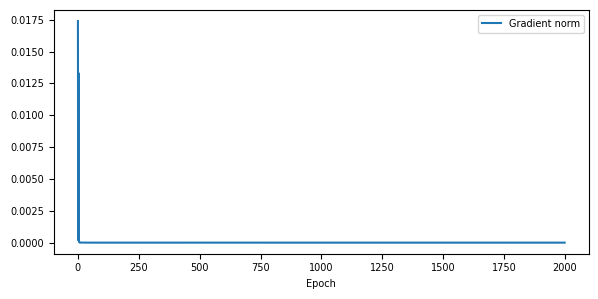

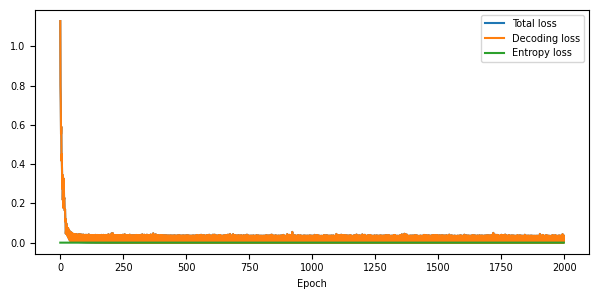

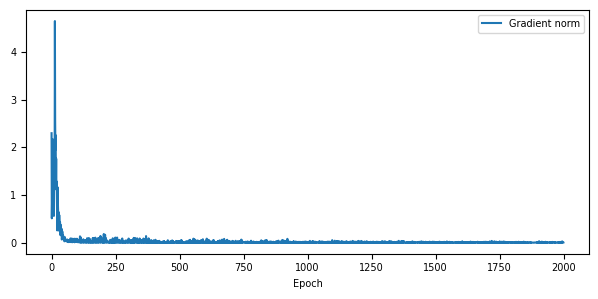

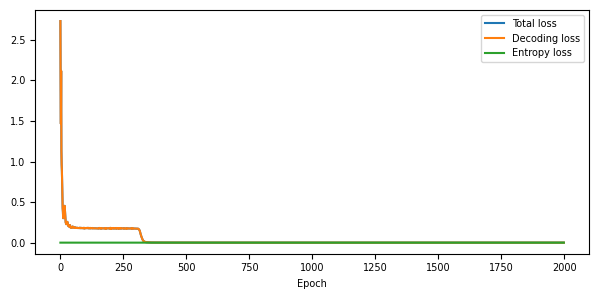

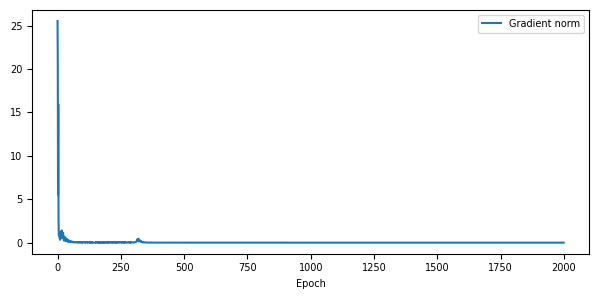

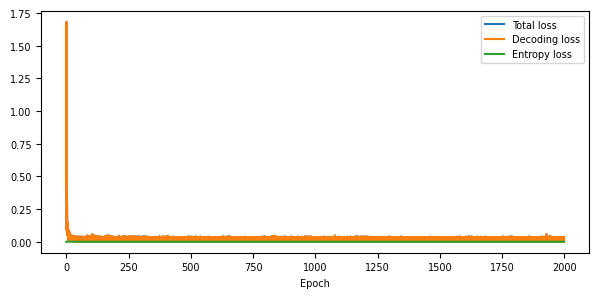

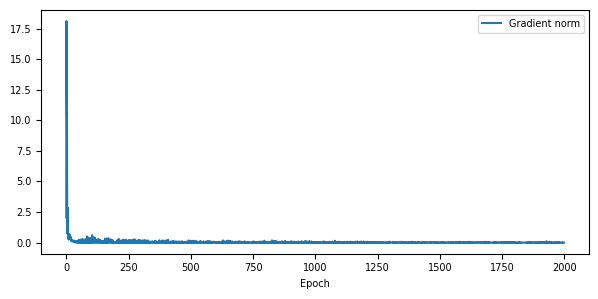

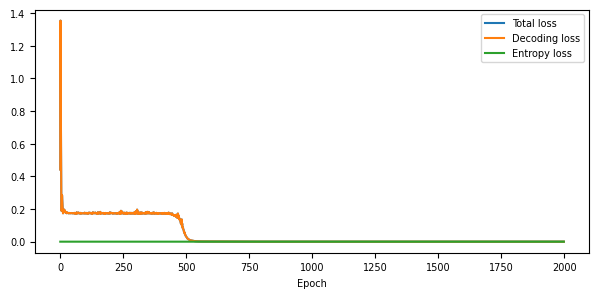

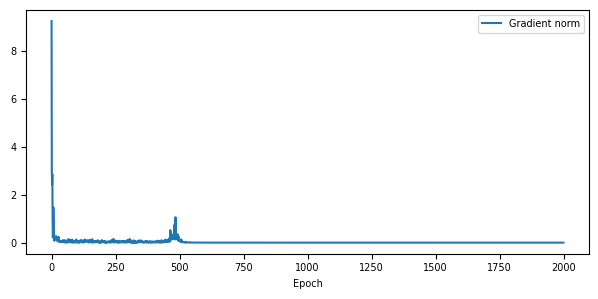

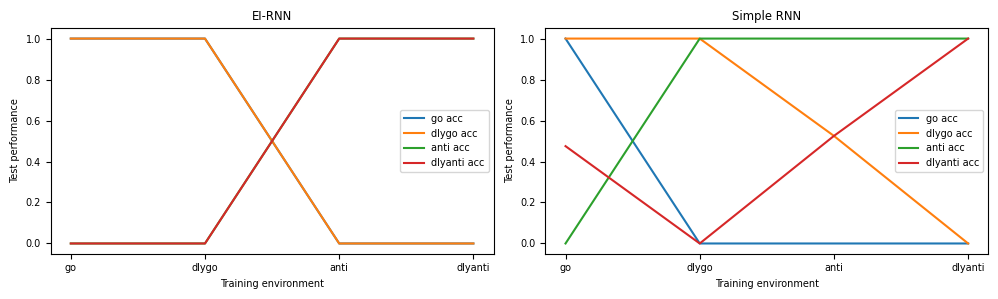

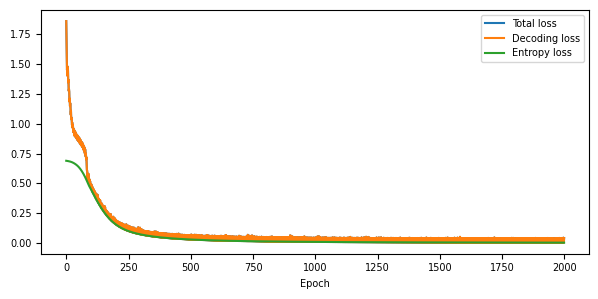

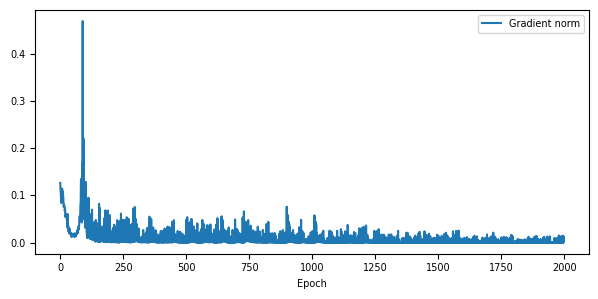

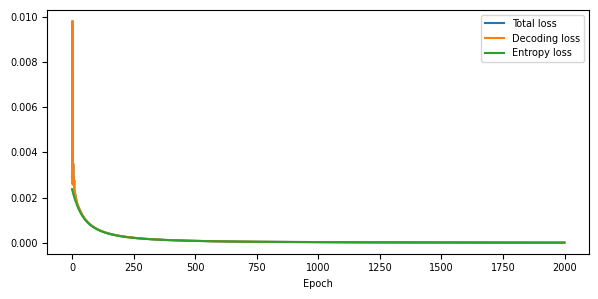

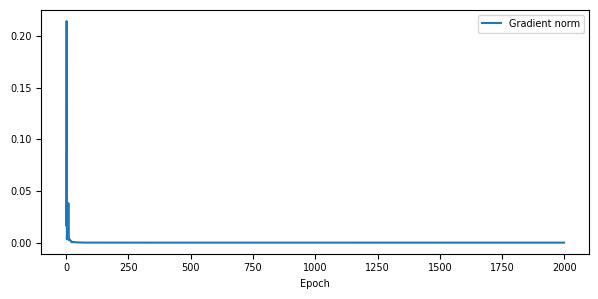

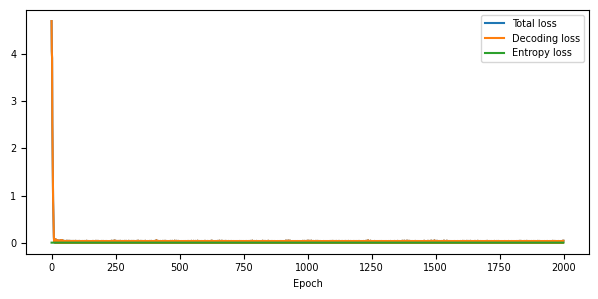

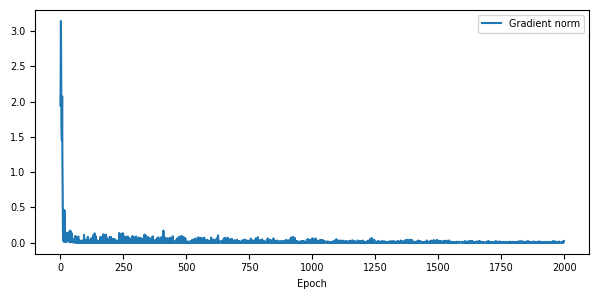

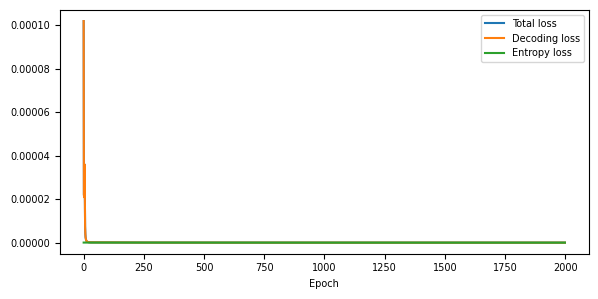

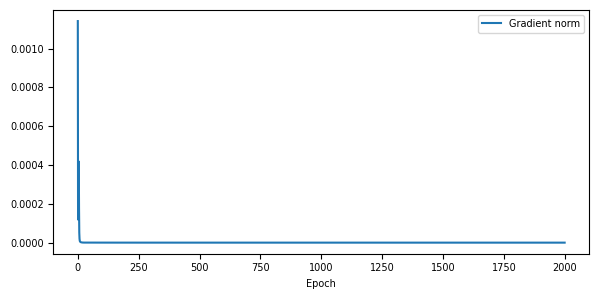

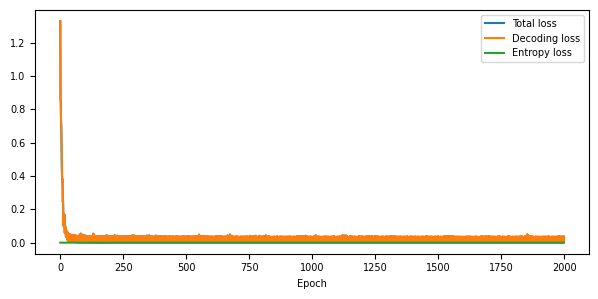

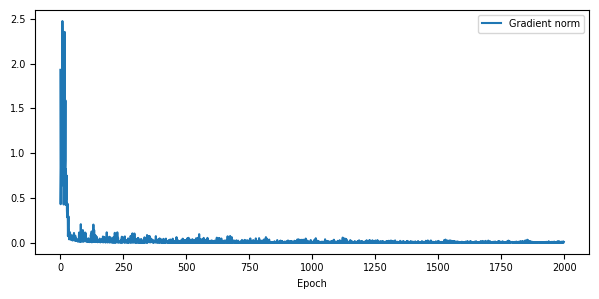

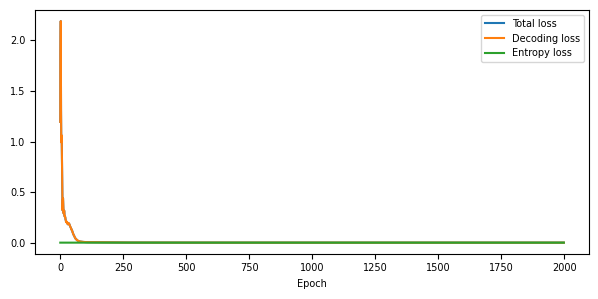

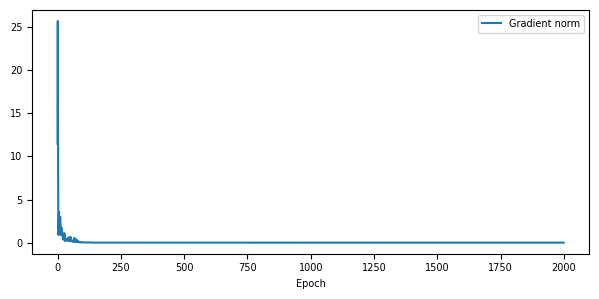

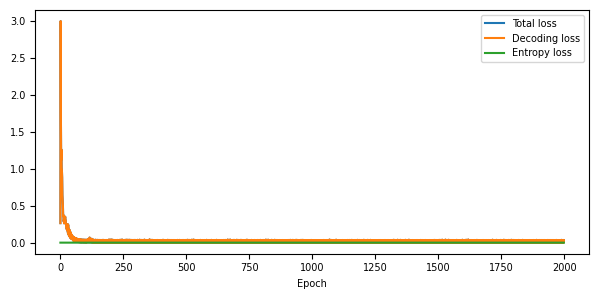

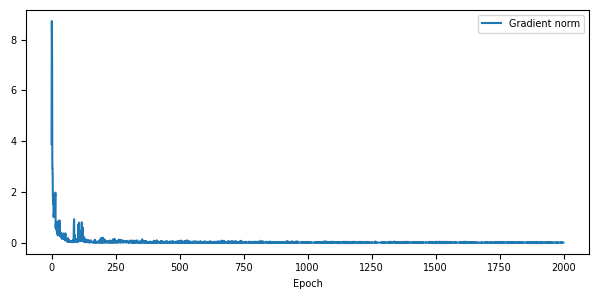

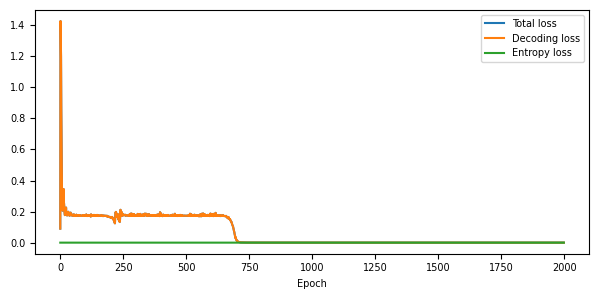

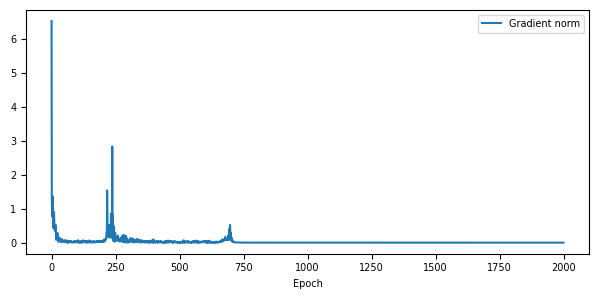

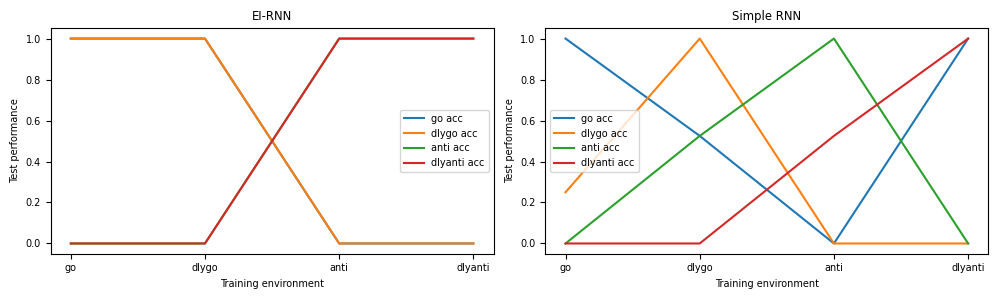

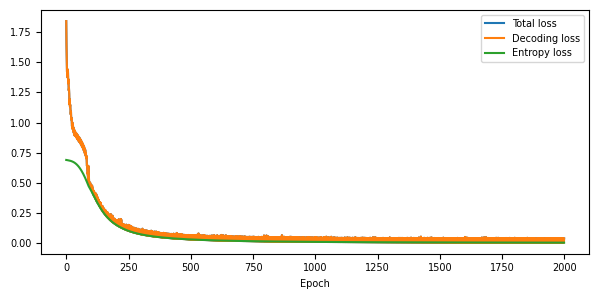

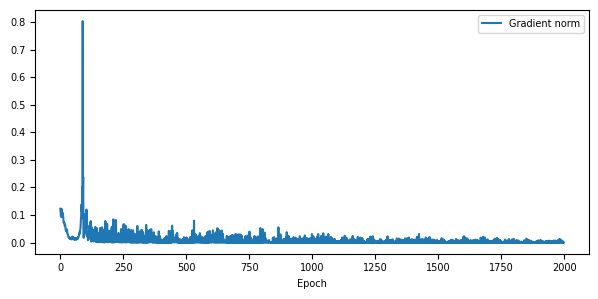

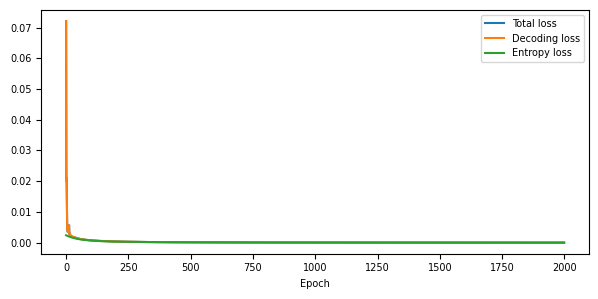

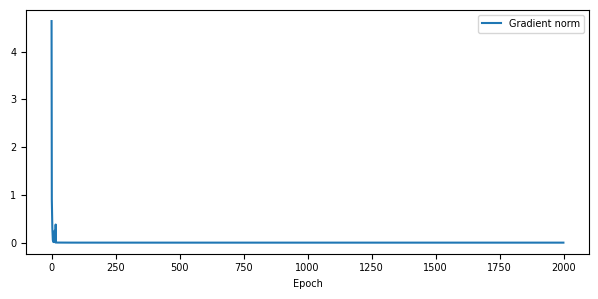

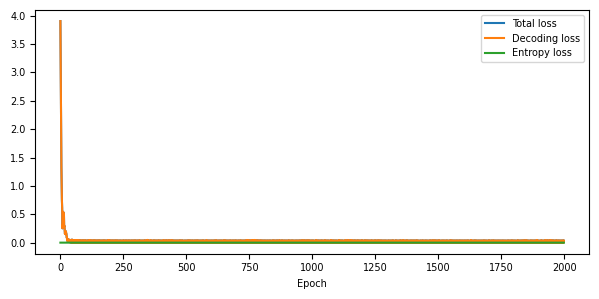

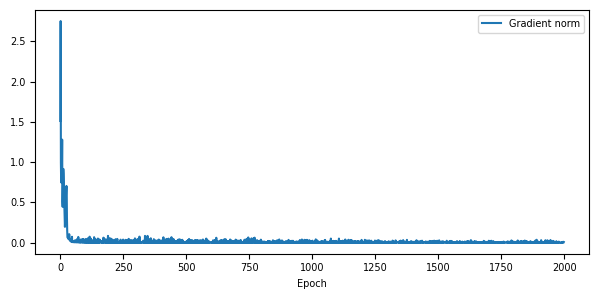

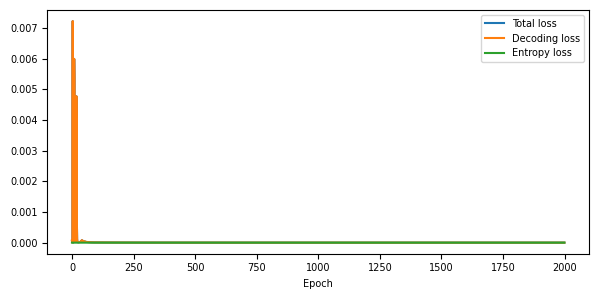

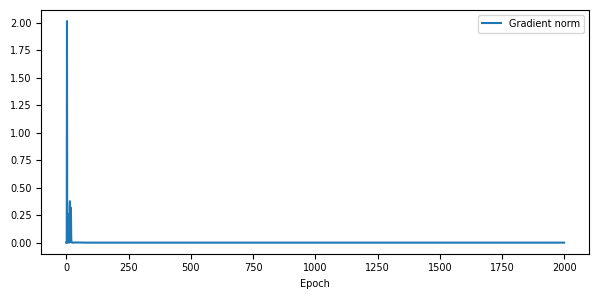

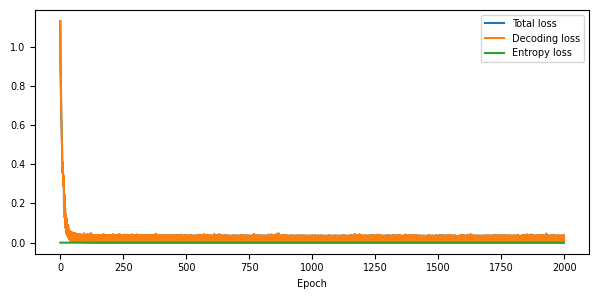

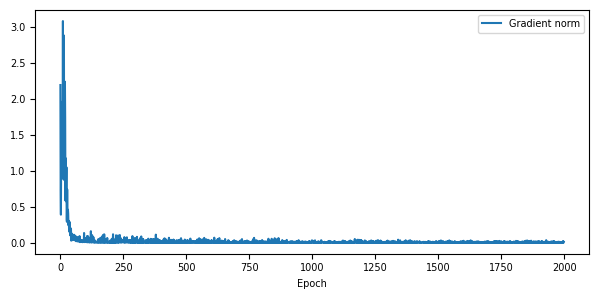

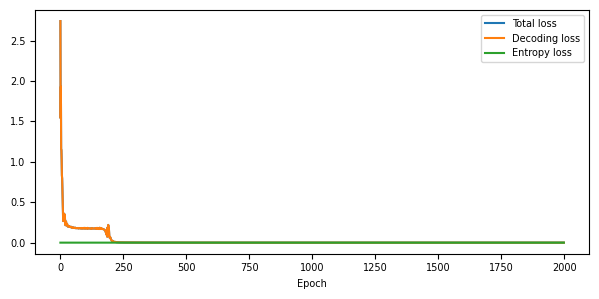

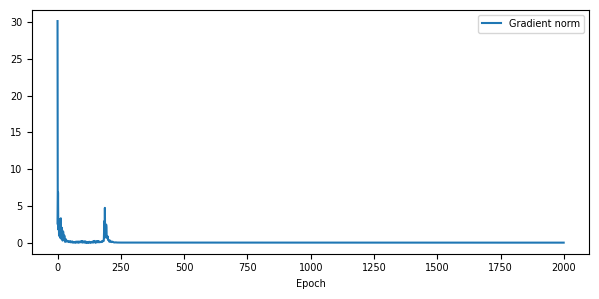

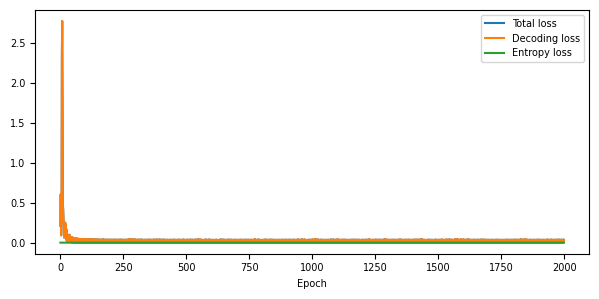

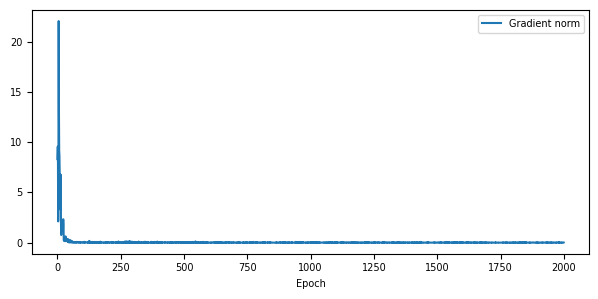

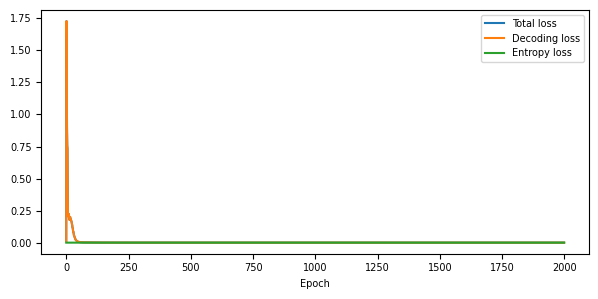

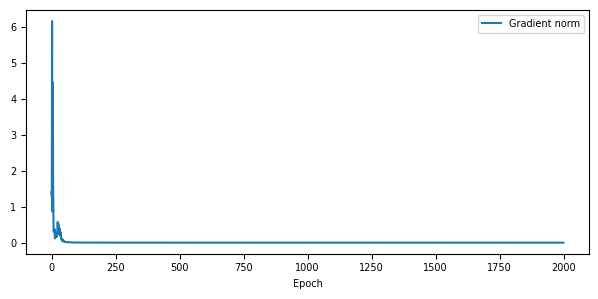

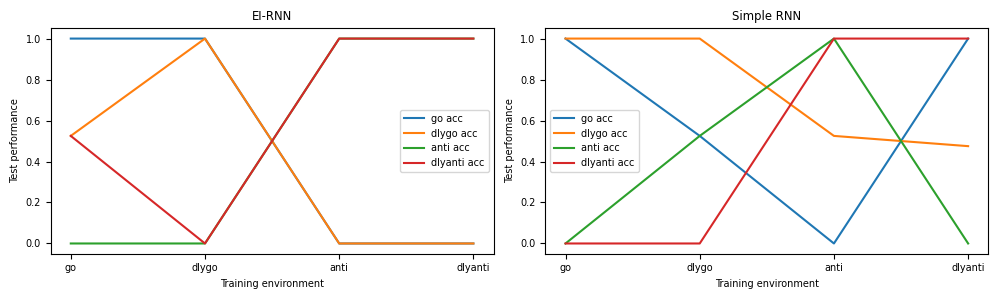

In [9]:
n_seed = 5
test_perf_EI_all = np.zeros((n_seed, len(envs), len(envs)))
test_perf_simple_all = np.zeros((n_seed, len(envs), len(envs)))
for i in range(n_seed):
    np.random.seed(i)
    torch.manual_seed(i)
    net = Net(num_h=64, ob_size=ob_size+len(envs), act_size=act_size, entropy_loss=True).to(device)
    simple_net = SimpleNet(num_h=64, ob_size=ob_size+len(envs), act_size=act_size).to(device)
    test_perf_EI = continual_learning(envs, net, prefix=f'EI_{i}')
    test_perf_simple = continual_learning(envs, simple_net, prefix=f'simple_{i}')
    test_perf_EI_all[i] = test_perf_EI
    test_perf_simple_all[i] = test_perf_simple
    plot_sequential_performance(test_perf_EI, test_perf_simple, i, task_ids)

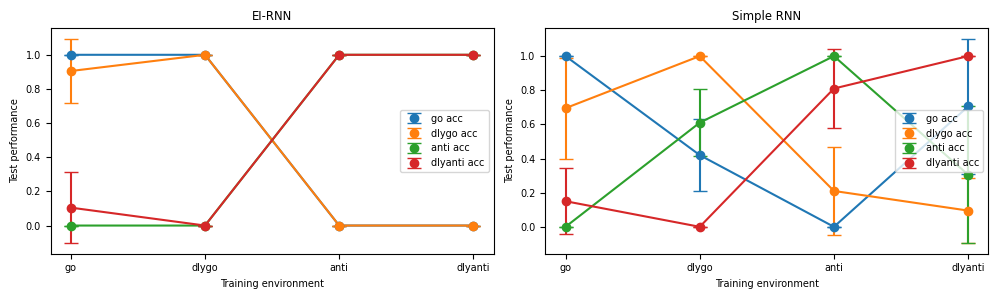

In [10]:
test_perf_EI_mean = np.mean(test_perf_EI_all, axis=0)
test_perf_simple_mean = np.mean(test_perf_simple_all, axis=0)
test_perf_EI_std = np.std(test_perf_EI_all, axis=0)
test_perf_simple_std = np.std(test_perf_simple_all, axis=0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
for i in range(test_perf_EI_mean.shape[1]):
    ax[0].plot(test_perf_EI_mean[:,i], color=colors[i])
    ax[0].errorbar(
        range(len(task_ids)),
        test_perf_EI_mean[:,i],
        yerr=test_perf_EI_std[:,i],
        fmt='o',
        capsize=5,
        label=f'{task_ids[i]} acc',
        color=colors[i]
    )
    ax[1].plot(test_perf_simple_mean[:,i], color=colors[i])
    ax[1].errorbar(
        range(len(task_ids)),
        test_perf_simple_mean[:,i],
        yerr=test_perf_simple_std[:,i],
        fmt='o',
        capsize=5,
        label=f'{task_ids[i]} acc',
        color=colors[i]
    )
ax[0].set_title('EI-RNN')
ax[1].set_title('Simple RNN')
for i in range(2):
    ax[i].set_xticks(range(len(task_ids)))
    ax[i].set_xticklabels(task_ids)
    # ax[i].set_xmargin(0)
    ax[i].set_xlabel('Training environment')
    ax[i].set_ylabel('Test performance')
    ax[i].legend()
plt.tight_layout()
plt.savefig(f'./output/sequential_performance.png')

In [11]:
print(test_perf_simple)

[[1.    1.    0.    0.   ]
 [0.525 1.    0.525 0.   ]
 [0.    0.525 1.    1.   ]
 [1.    0.475 0.    1.   ]]


In [12]:
net.lstm.Wrec_free.grad.norm(2)

tensor(3.2839e-07, device='cuda:0')

Percentage of excitatory neurons: 0.44
[ 0  1  3  6 11 16 17 19 20 21 24 25 27 28 34 35 39 40 43 44 45 47 48 51
 55 58 59 60]


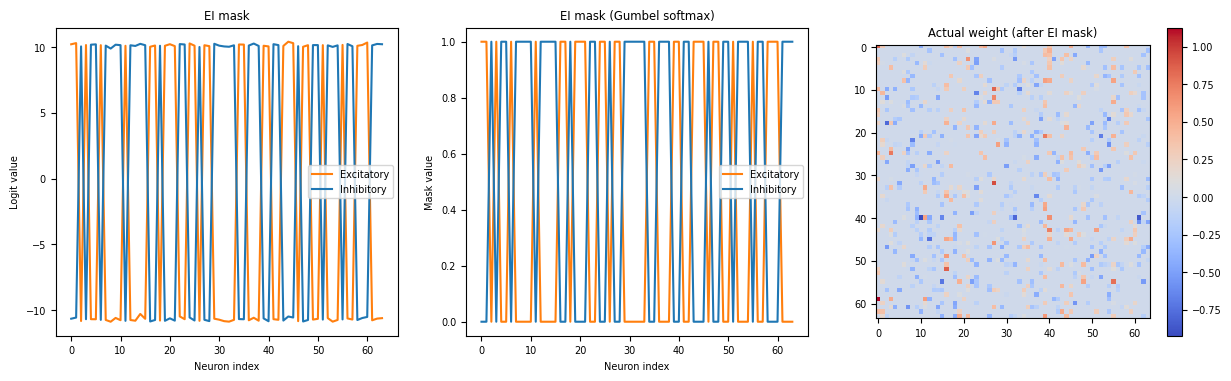

In [13]:
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
ei_code = np.where(eimask[:, 0] > eimask[:, 1], 1., -1.)
mask = np.where(ei_code.reshape(-1,1)>0, np.array([[1,0]]).repeat(eimask.shape[0], axis=0),
                np.array([[0,1]]).repeat(eimask.shape[0], axis=0))
# Apply the mask to the weight
weight = net.lstm.Wrec_free
corrected_weight = net.lstm.rec_filter(weight).detach().cpu().numpy()  # Apply the rectifier
actual_weight = corrected_weight @ np.diag(ei_code)  # Apply the mask to the weight
fig, ax = plt.subplots(1,3,figsize=(15, 4))
ax[0].plot(eimask[:, 0], label='Excitatory', color='C1')
ax[0].plot(eimask[:, 1], label='Inhibitory', color='C0')
ax[0].set_title('EI mask')
ax[0].set_xlabel('Neuron index')
ax[0].set_ylabel('Logit value')
ax[0].legend()
ax[1].plot(mask[:, 0], label='Excitatory', color='C1')
ax[1].plot(mask[:, 1], label='Inhibitory', color='C0')
ax[1].set_title('EI mask (Gumbel softmax)')
ax[1].set_xlabel('Neuron index')
ax[1].set_ylabel('Mask value')
ax[1].legend()
# normalized_weight = (actual_weight - np.min(actual_weight))/(np.max(actual_weight) - np.min(actual_weight)) * 2 - 1  # Normalize to [-1, 1]
im = ax[2].imshow(actual_weight, cmap='coolwarm')
ax[2].set_title('Actual weight (after EI mask)')
plt.colorbar(im, ax=ax[2])
excitatory_neurons = np.where(mask[:, 0] > mask[:, 1],1,0).mean()
print(f'Percentage of excitatory neurons: {excitatory_neurons:.2f}')
print(np.where(mask[:, 0] > mask[:, 1])[0])

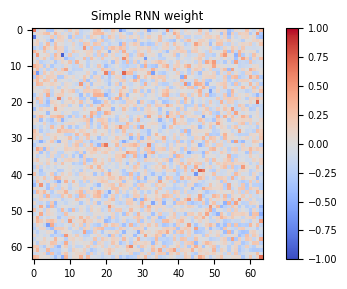

In [14]:
simple_weight = simple_net.lstm.Wrec_free.detach().cpu().numpy()
fig, ax = plt.subplots(1, 1, figsize=(6, 3))
im = ax.imshow(simple_weight, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_title('Simple RNN weight')
plt.colorbar(im, ax=ax)

In [15]:
print((np.abs(simple_weight)>0.1).mean())
print((np.abs(actual_weight)>0.1).mean())

0.599609375
0.149658203125


In [16]:
# net = Net(num_h=64, ob_size=ob_size, act_size=act_size, entropy_loss=True).to(device)
# net = train(env1, net)
# print(test(env1, net))

In [17]:
# net = train(env2, net)
# print(test(env2, net))
# print(test(env1, net))

In [18]:
# net = SimpleNet(num_h=64, ob_size=ob_size, act_size=act_size).to(device)
# net = train(env1, net)
# print(test(env1, net))

In [19]:
# net = Net(num_h=64, ob_size=ob_size, act_size=act_size, entropy_loss=True).to(device)
# test_perf_EI = continual_learning([env1, env2], net)
# net = SimpleNet(num_h=64, ob_size=ob_size, act_size=act_size).to(device)
# test_perf_simple = continual_learning([env1, env2], net)

In [20]:
# def train(env, net):
#     seq_len = 100
#     batch_size = 32

#     criterion = nn.CrossEntropyLoss()
#     optimizer = torch.optim.Adam(net.parameters(), lr=1e-2)
#     dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

#     running_loss = 0.0
#     running_entropy = 0.0
#     running_decoding_loss = 0.0
#     for i in range(EPOCHS):
#         # net.set_temperature(get_temperature(i))
#         # if i % 10 == 9:
#             # print('Epoch:', i+1, 'Temperature:', net.temperature)
#         inputs, labels = dataset()
#         inputs = torch.from_numpy(inputs).type(torch.float).to(device)
#         labels = torch.from_numpy(labels.flatten()).type(torch.long).to(device)

#         # zero the parameter gradients
#         optimizer.zero_grad()

#         # forward + backward + optimize
#         outputs, eimask_logit, hidden = net(inputs)

#         # eimask_prob = F.softmax(eimask_logit, dim=-1)
#         # eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)

#         decoding_loss = criterion(outputs.view(-1, act_size), labels)
#         # entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization

#         # loss = decoding_loss
#         loss = decoding_loss

#         loss.backward()
#         optimizer.step()

#         # print statistics
#         running_loss += loss.item()
#         # running_entropy += entropy_loss.item()
#         running_decoding_loss += decoding_loss.item()
#         if (i+1) % 100 == 0:
#             print('{:d} loss: {:0.5f}'.format(i+1, running_loss / 100))
#             print('Entropy loss: {:0.5f}, Decoding loss: {:0.5f}'.format(
#                 running_entropy / 100, running_decoding_loss / 100))
#             running_loss = 0.0

#     print('Finished Training')
#     return net

In [21]:
# EI_env2_performance = [0.995, 1.0]
# simple_env2_performance = [1.0, 0.545]
# fig, ax = plt.subplots(figsize=(4,3))
# ax.plot(EI_env2_performance, label='EI', marker='o')
# ax.plot(simple_env2_performance, label='Simple', marker='o')
# ax.set_xticks([0, 1])
# ax.set_xticklabels(['Delay-Go', 'MultiDM'])
# ax.set_ylabel('Test performance on Delay-Go')
# ax.set_xlabel('Training task')
# plt.legend()
# plt.tight_layout()
# plt.show()
